# Loan Default Prediction System

## Project goal
Predict whether a loan record is likely to default (`Default = 1`) or not (`Default = 0`) using the supplied LendingClub-style loan dataset.

## Project workflow
1. Load and validate the dataset.
2. Explore target balance, missing values, numeric distributions, correlations, default rates by selected categories, and default rates over time when a date field exists.
3. Prepare features and remove target, identifier, and commonly post-outcome fields.
4. Split the data into train, validation, and test sets. Use chronological 70/15/15 splitting when a supported date field is sufficiently parseable; otherwise use a stratified random split.
5. Train and compare Logistic Regression, Decision Tree, and Random Forest.
6. Select the model with the highest validation PR-AUC and evaluate it once on the held-out test set.



In [2]:
from pathlib import Path
import re
import json
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, f1_score, precision_score,
    recall_score, roc_auc_score
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


warnings.filterwarnings("ignore")
RANDOM_STATE = 42
TARGET = "Default"


## 2. Load and validate the dataset

Place `LC_loans_granting_model_dataset.csv` in the project folder or update `DATA_PATH` below. The target should represent the outcome of interest and be encoded as 0/1, Yes/No, Y/N, or Default/Non-default.


In [3]:
DATA_PATH = Path(r"C:\\Users\\abhis\\Downloads\\loan_default_prediction_project\\loan_default_prediction_project\\Dataset\\LC_loans_granting_model_dataset.csv")
# Example if the file is inside Dataset:
# DATA_PATH = Path("Dataset/LC_loans_granting_model_dataset.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH.resolve()}. Update DATA_PATH to the CSV location."
    )

df = pd.read_csv(DATA_PATH, low_memory=False)
df.columns = [str(col).strip() for col in df.columns]

if TARGET not in df.columns:
    raise ValueError(f"Target column '{TARGET}' not found. Available columns: {df.columns.tolist()}")

def normalize_target(series):
    if pd.api.types.is_numeric_dtype(series):
        result = pd.to_numeric(series, errors="coerce")
    else:
        normalized = series.astype("string").str.strip().str.lower()
        mapping = {
            "0": 0, "1": 1, "false": 0, "true": 1, "no": 0, "yes": 1,
            "non-default": 0, "non_default": 0, "default": 1, "n": 0, "y": 1
        }
        mapped = normalized.map(mapping)
        result = mapped if mapped.notna().all() else pd.to_numeric(normalized, errors="coerce")
    return result

df[TARGET] = normalize_target(df[TARGET])
df = df[df[TARGET].isin([0, 1])].copy()
df[TARGET] = df[TARGET].astype("int8")

if df.empty or df[TARGET].nunique() < 2:
    raise ValueError("The target must contain both classes (0 and 1).")

print(f"Rows: {len(df):,}")
print(f"Columns: {len(df.columns)}")
display(df.head())
display(df.dtypes.astype(str).rename("dtype").to_frame())


Rows: 1,347,681
Columns: 15


,id,issue_d,revenue,dti_n,loan_amnt,fico_n,experience_c,emp_length,purpose,home_ownership_n,addr_state,zip_code,Default,title,desc
0,68407277,Dec-2015,55000.0,5.91,3600,677.0,1,10+ years,debt_consolidation,MORTGAGE,PA,190xx,0,Debt consolidation,NaN
1,68355089,Dec-2015,65000.0,16.06,24700,717.0,1,10+ years,small_business,MORTGAGE,SD,577xx,0,Business,NaN
2,68341763,Dec-2015,71000.0,13.85,20000,697.0,1,10+ years,home_improvement,MORTGAGE,IL,605xx,0,NaN,NaN
3,68476807,Dec-2015,104433.0,25.37,10400,697.0,1,3 years,major_purchase,MORTGAGE,PA,174xx,0,Major purchase,NaN
4,68426831,Dec-2015,34000.0,10.20,11950,692.0,1,4 years,debt_consolidation,RENT,GA,300xx,0,Debt consolidation,NaN


,dtype
id,int64
issue_d,str
revenue,float64
dti_n,float64
loan_amnt,int64
fico_n,float64
experience_c,int64
emp_length,str
purpose,str
home_ownership_n,str


## 3. Exploratory Data Analysis (EDA)

The charts below are descriptive. Differences in default rates show associations in this dataset and do not prove causation.

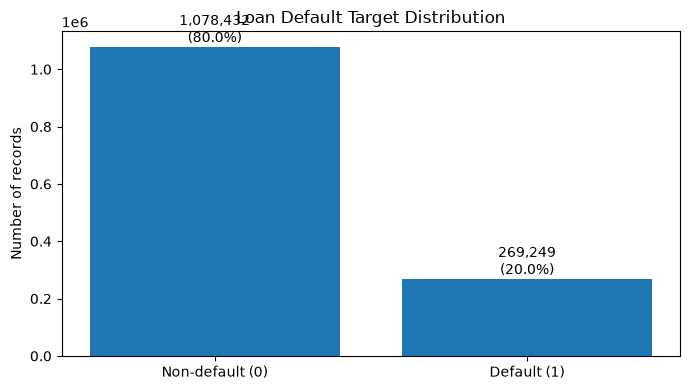

Target proportions:


,percent
Default,
0,80.021311
1,19.978689


In [4]:
# Target distribution
target_counts = df[TARGET].value_counts().reindex([0, 1], fill_value=0)
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(["Non-default (0)", "Default (1)"], target_counts.values)
ax.set_title("Loan Default Target Distribution")
ax.set_ylabel("Number of records")
for bar, count in zip(bars, target_counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
            f"{count:,}\n({count / len(df):.1%})", ha="center", va="bottom")
plt.tight_layout()
plt.show()

print("Target proportions:")
display((df[TARGET].value_counts(normalize=True).sort_index() * 100).rename("percent").to_frame())


,missing_percent
desc,91.162671
title,1.235975
zip_code,0.000074
dti_n,0.000000
id,0.000000
issue_d,0.000000
revenue,0.000000
experience_c,0.000000
fico_n,0.000000
loan_amnt,0.000000


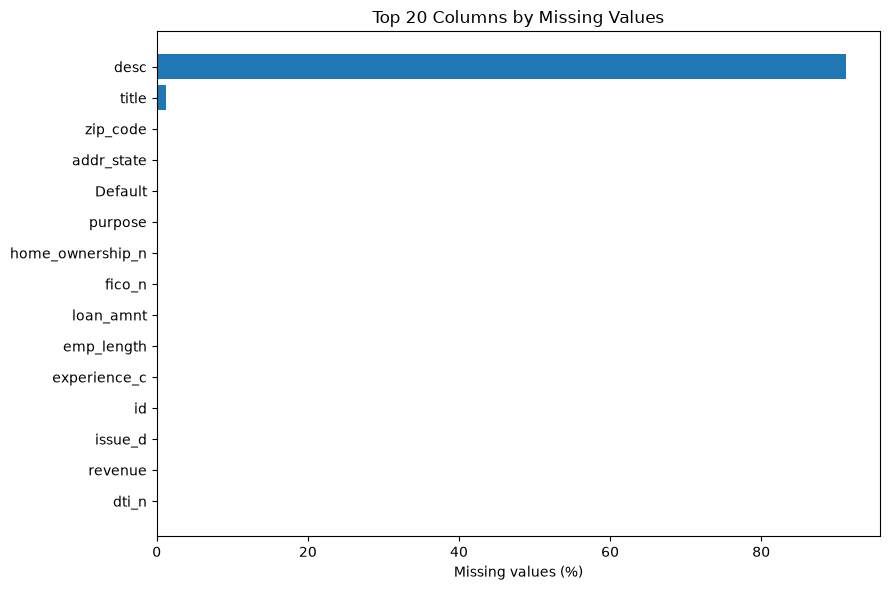

In [5]:
# Missing-value summary
missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)
display(missing_pct.head(20).rename("missing_percent").to_frame())

top_missing = missing_pct.head(20).sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top_missing.index.astype(str), top_missing.values)
ax.set_title("Top 20 Columns by Missing Values")
ax.set_xlabel("Missing values (%)")
plt.tight_layout()
plt.show()


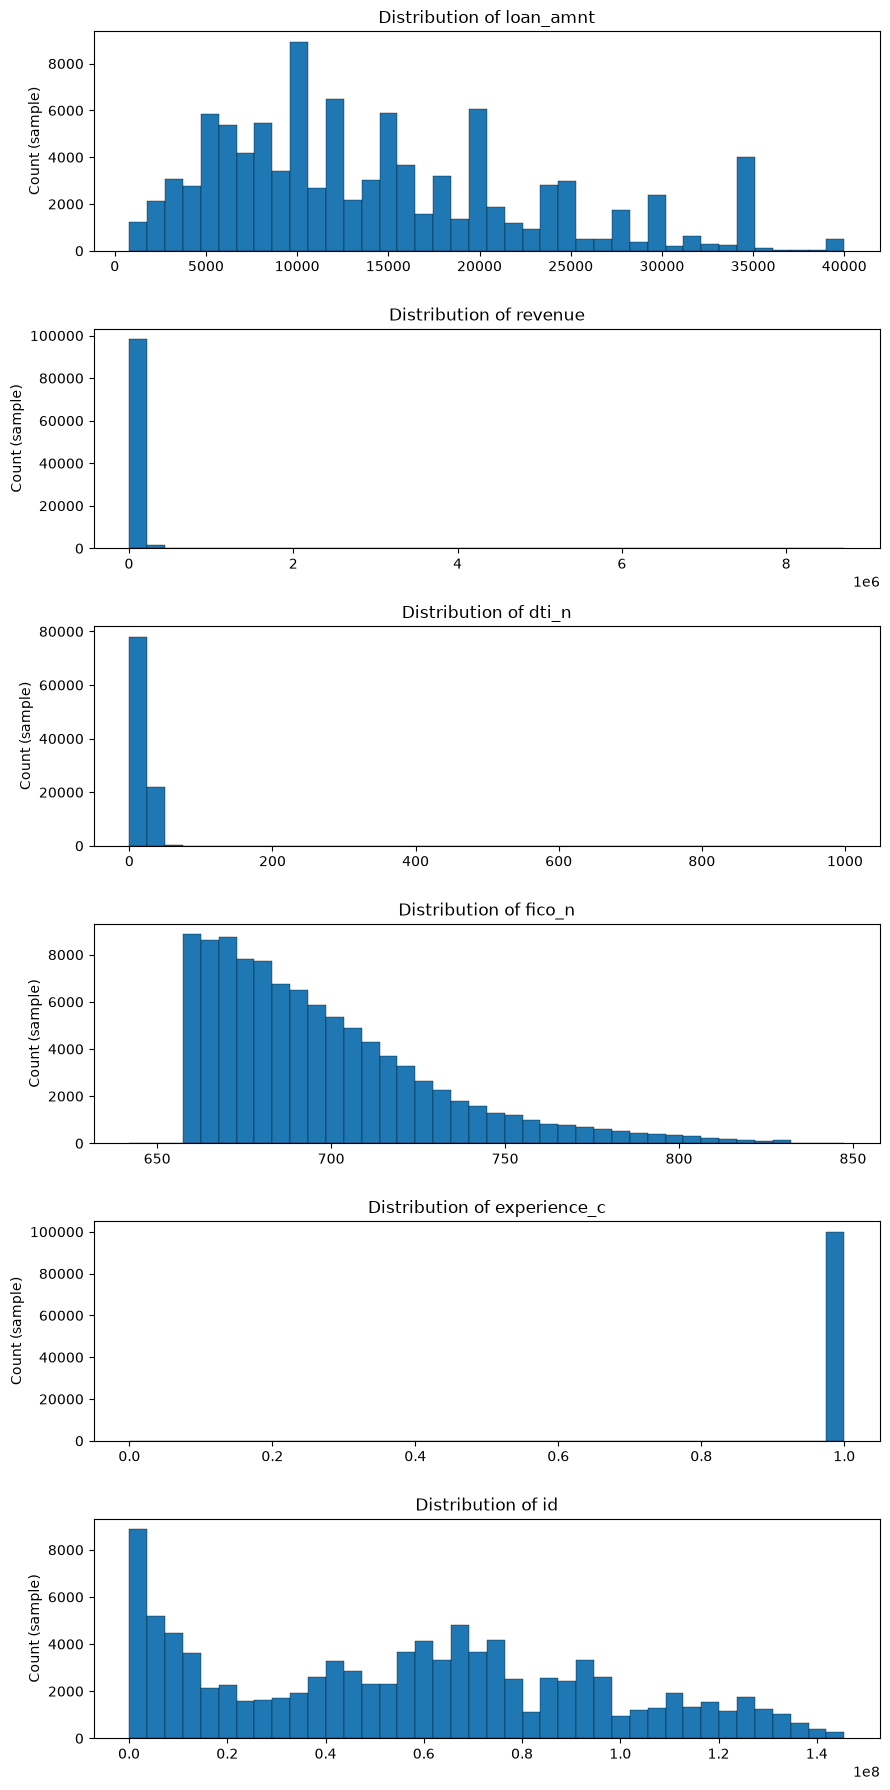

In [6]:
# Numeric distributions on a reproducible sample to keep plots manageable
plot_df = df.sample(n=min(len(df), 100_000), random_state=RANDOM_STATE).copy()
preferred_numeric = [c for c in ["loan_amnt", "revenue", "dti_n", "fico_n", "experience_c"] if c in df.columns]
for col in df.select_dtypes(include=np.number).columns:
    if col != TARGET and col not in preferred_numeric:
        preferred_numeric.append(col)
preferred_numeric = preferred_numeric[:6]

if preferred_numeric:
    fig, axes = plt.subplots(len(preferred_numeric), 1, figsize=(9, 3 * len(preferred_numeric)))
    if len(preferred_numeric) == 1:
        axes = [axes]
    for ax, col in zip(axes, preferred_numeric):
        values = pd.to_numeric(plot_df[col], errors="coerce").replace([np.inf, -np.inf], np.nan).dropna()
        if len(values):
            ax.hist(values, bins=40, edgecolor="black", linewidth=0.25)
            ax.set_title(f"Distribution of {col}")
            ax.set_ylabel("Count (sample)")
    plt.tight_layout()
    plt.show()
else:
    print("No numeric predictors available for distribution plots.")


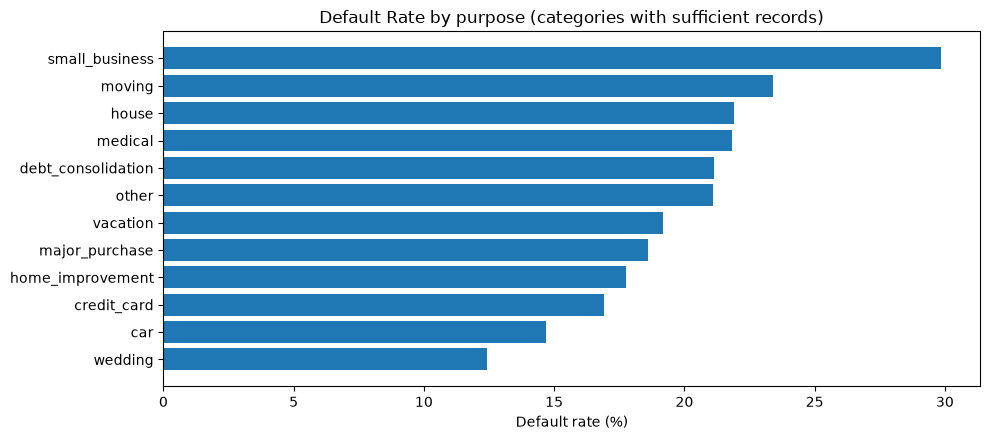

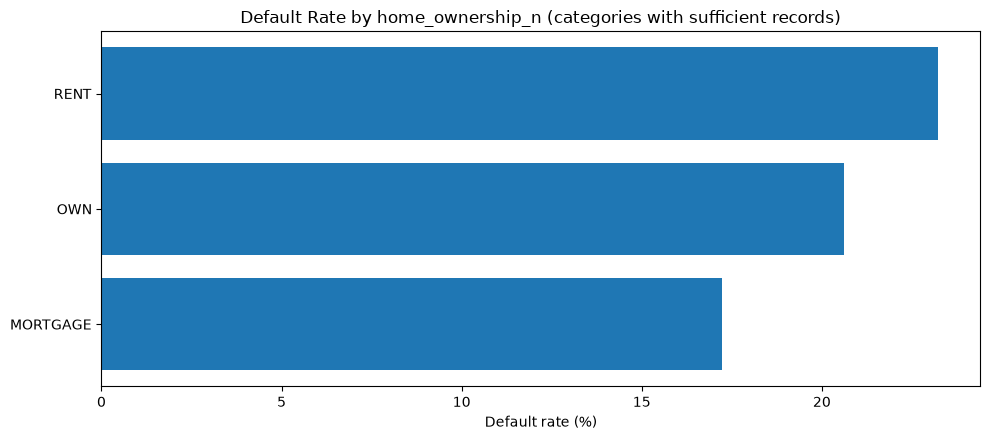

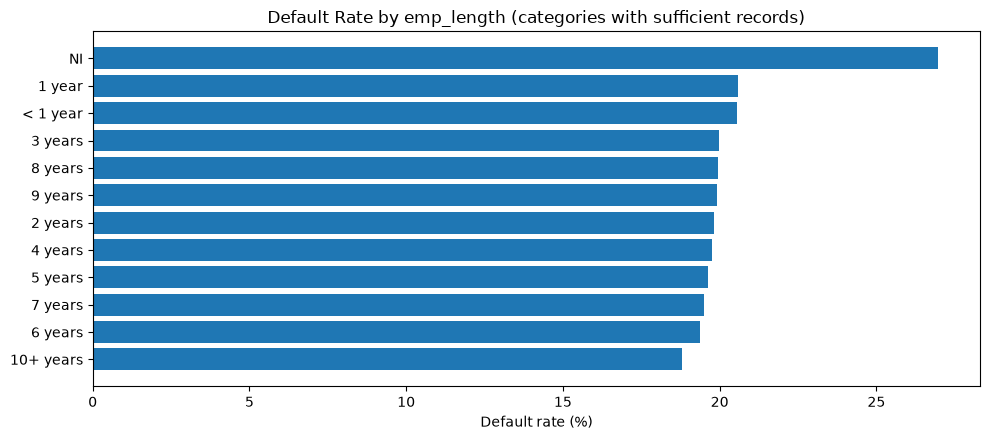

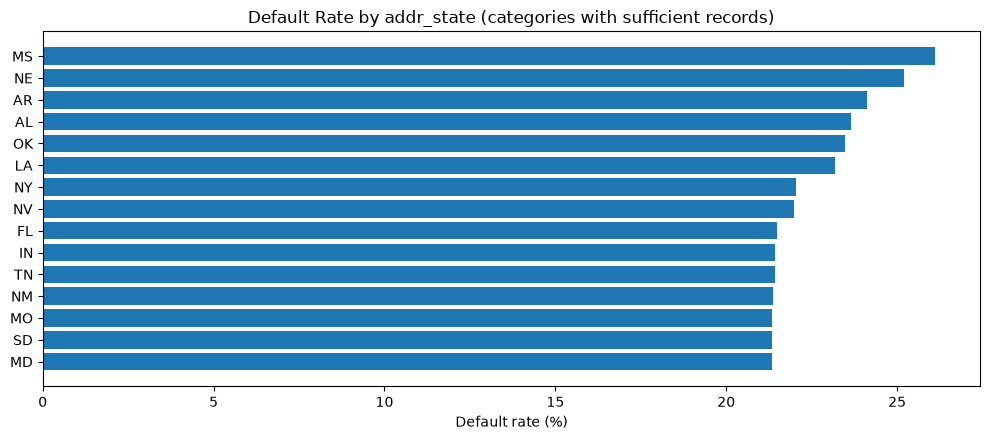

,feature,category,default_rate_percent,count
0,purpose,small_business,29.855538,15575
1,purpose,moving,23.413866,9520
2,purpose,house,21.908418,7294
3,purpose,medical,21.844163,15606
4,purpose,debt_consolidation,21.154215,781206
5,purpose,other,21.084037,78263
6,purpose,vacation,19.189695,9083
7,purpose,major_purchase,18.603392,29543
8,purpose,home_improvement,17.756945,87684
9,purpose,credit_card,16.931088,295551


In [7]:
# Default rates by selected categorical features
cat_candidates = [c for c in ["purpose", "home_ownership_n", "emp_length", "addr_state"] if c in df.columns]
if not cat_candidates:
    cat_candidates = [c for c in df.select_dtypes(exclude=np.number).columns if c != TARGET][:4]

eda_category_summaries = []
for col in cat_candidates:
    tmp = df[[col, TARGET]].copy()
    tmp[col] = tmp[col].astype("string").fillna("Missing")
    grouped = tmp.groupby(col, dropna=False)[TARGET].agg(["mean", "count"]).reset_index()
    grouped = grouped[grouped["count"] >= max(30, int(0.001 * len(df)))].sort_values("mean", ascending=False).head(15)
    for _, row in grouped.iterrows():
        eda_category_summaries.append({
            "feature": col, "category": str(row[col]),
            "default_rate_percent": float(row["mean"] * 100), "count": int(row["count"])
        })
    if not grouped.empty:
        grouped = grouped.sort_values("mean")
        fig, ax = plt.subplots(figsize=(10, 4.5))
        ax.barh(grouped[col].astype(str), grouped["mean"] * 100)
        ax.set_title(f"Default Rate by {col} (categories with sufficient records)")
        ax.set_xlabel("Default rate (%)")
        plt.tight_layout()
        plt.show()

category_summary = pd.DataFrame(eda_category_summaries)
display(category_summary.head(30))


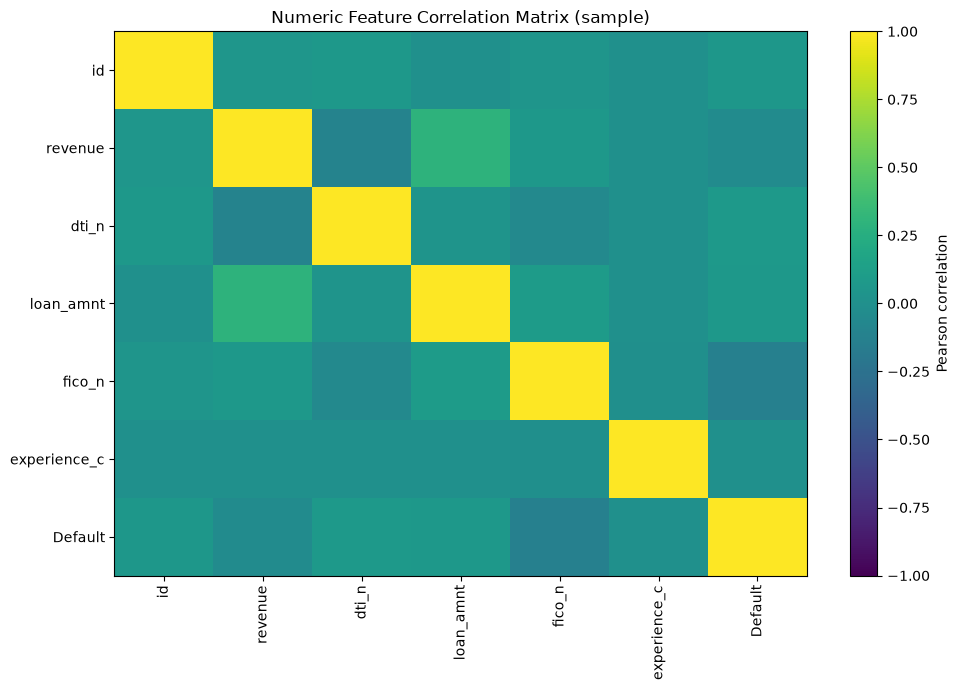

,id,revenue,dti_n,loan_amnt,fico_n,experience_c,Default
id,1.000000,0.047293,0.066701,0.007756,0.042076,0.006528,0.055918
revenue,0.047293,1.000000,-0.102088,0.295271,0.067924,0.001439,-0.034539
dti_n,0.066701,-0.102088,1.000000,0.036338,-0.059480,0.004027,0.084227
loan_amnt,0.007756,0.295271,0.036338,1.000000,0.097750,0.006353,0.066223
fico_n,0.042076,0.067924,-0.059480,0.097750,1.000000,-0.002990,-0.127046
experience_c,0.006528,0.001439,0.004027,0.006353,-0.002990,1.000000,0.002223
Default,0.055918,-0.034539,0.084227,0.066223,-0.127046,0.002223,1.000000


In [8]:
# Correlation matrix for a sample of numeric columns
corr_cols = [c for c in df.select_dtypes(include=np.number).columns if c != TARGET][:12]
if TARGET in df.columns:
    corr_cols = corr_cols + [TARGET]
if len(corr_cols) >= 2:
    corr = plot_df[corr_cols].corr(numeric_only=True)
    fig, ax = plt.subplots(figsize=(10, 7))
    image = ax.imshow(corr, aspect="auto", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr.columns)))
    ax.set_xticklabels(corr.columns, rotation=90)
    ax.set_yticks(range(len(corr.index)))
    ax.set_yticklabels(corr.index)
    ax.set_title("Numeric Feature Correlation Matrix (sample)")
    fig.colorbar(image, ax=ax, label="Pearson correlation")
    plt.tight_layout()
    plt.show()
    display(corr)
else:
    print("Not enough numeric columns for a correlation matrix.")


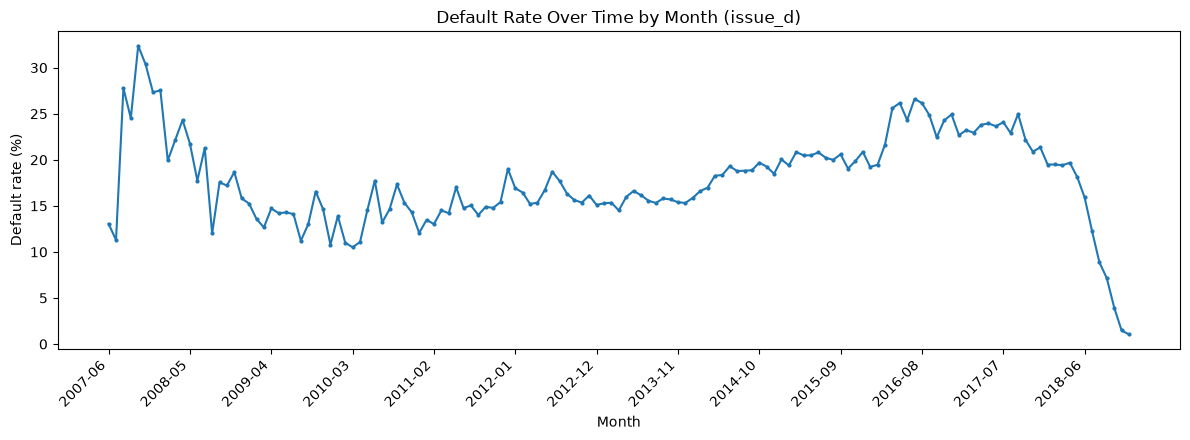

In [9]:
# Default rate over time, if a recognized issue/origination date is present
DATE_CANDIDATES = ["issue_d", "issue_date", "loan_issue_date", "origination_date", "application_date", "date"]
lower_to_original = {str(col).lower(): col for col in df.columns}
date_col = next((lower_to_original[name] for name in DATE_CANDIDATES if name in lower_to_original), None)

def parse_dates(series):
    parsed = pd.to_datetime(series, errors="coerce")
    if parsed.notna().mean() < 0.5:
        parsed = pd.to_datetime(series.astype(str), format="%b-%Y", errors="coerce")
    return parsed

if date_col:
    dates = parse_dates(df[date_col])
    temporal = pd.DataFrame({"date": dates, TARGET: df[TARGET]}).dropna(subset=["date"])
    if not temporal.empty:
        temporal["month"] = temporal["date"].dt.to_period("M").astype(str)
        by_month = temporal.groupby("month")[TARGET].agg(["mean", "count"]).reset_index()
        fig, ax = plt.subplots(figsize=(12, 4.5))
        ax.plot(by_month["month"], by_month["mean"] * 100, marker="o", markersize=2)
        ax.set_title(f"Default Rate Over Time by Month ({date_col})")
        ax.set_ylabel("Default rate (%)")
        ax.set_xlabel("Month")
        step = max(1, len(by_month) // 12)
        ax.set_xticks(range(0, len(by_month), step))
        ax.set_xticklabels(by_month["month"].iloc[::step], rotation=45, ha="right")
        plt.tight_layout()
        plt.show()
    else:
        print(f"Date column '{date_col}' exists, but could not be parsed.")
else:
    print("No recognized issue/origination date column found; temporal EDA and chronological split will not be used.")


## 4. Feature preparation and data splitting

The notebook excludes the target, common identifiers, and several columns that are often only known after loan outcomes. This is a conservative name-based filter, **not a guarantee against leakage**. Inspect the data dictionary and confirm every retained feature is available at the time an application is assessed.


In [10]:
POST_OUTCOME_PATTERNS = [
    r"^default_reason$", r"^last_pymnt", r"^next_pymnt", r"^total_pymnt",
    r"^total_rec", r"^recoveries$", r"^collection_recovery", r"^out_prncp",
    r"^outstanding", r"^settlement", r"^hardship", r"^loan_status$",
    r"^default_date$", r"^chargeoff", r"^delinq_2yrs$", r"^last_credit_pull"
]
ID_PATTERNS = [r"^id$", r"^member_id$", r"^url$", r"^emp_title$"]

def select_features(frame, date_column=None):
    drop_cols = [TARGET]
    for col in frame.columns:
        low = str(col).lower().strip()
        if any(re.search(p, low) for p in POST_OUTCOME_PATTERNS + ID_PATTERNS):
            drop_cols.append(col)
    X = frame.drop(columns=list(set(drop_cols)), errors="ignore").copy()
    if date_column and date_column in X.columns:
        X = X.drop(columns=[date_column])
    X = X.dropna(axis=1, how="all")
    for col in X.columns:
        if pd.api.types.is_string_dtype(X[col]) or isinstance(X[col].dtype, pd.CategoricalDtype):
            X[col] = X[col].astype("object")
    return X

def split_dataset(frame, date_column):
    if date_column:
        dates = parse_dates(frame[date_column])
        if dates.notna().mean() >= 0.70:
            valid_rows = dates.notna()
            working = frame.loc[valid_rows].copy()
            working["_parsed_split_date"] = dates.loc[valid_rows]
            working = working.sort_values("_parsed_split_date").drop(columns=["_parsed_split_date"])
            n = len(working)
            if n >= 20:
                a, b = int(n * 0.70), int(n * 0.85)
                train_part, valid_part, test_part = working.iloc[:a].copy(), working.iloc[a:b].copy(), working.iloc[b:].copy()
                if all(part[TARGET].nunique() == 2 for part in [train_part, valid_part, test_part]):
                    return train_part, valid_part, test_part, f"chronological ({date_column})"
    train_val, test_part = train_test_split(frame, test_size=0.15, random_state=RANDOM_STATE, stratify=frame[TARGET])
    train_part, valid_part = train_test_split(train_val, test_size=0.1764705882, random_state=RANDOM_STATE, stratify=train_val[TARGET])
    return train_part.copy(), valid_part.copy(), test_part.copy(), "stratified random"

train_df, valid_df, test_df, split_method = split_dataset(df, date_col)
X_train = select_features(train_df, date_col)
X_valid = select_features(valid_df, date_col)
X_test = select_features(test_df, date_col)

# Keep only variable columns and columns with some training data; align validation/test schemas.
feature_columns = X_train.columns[X_train.nunique(dropna=False) > 1].tolist()
X_train = X_train[feature_columns].copy()
X_valid = X_valid.reindex(columns=feature_columns)
X_test = X_test.reindex(columns=feature_columns)

nonempty_columns = X_train.columns[~X_train.isna().all()].tolist()
X_train = X_train[nonempty_columns].copy()
X_valid = X_valid.reindex(columns=nonempty_columns)
X_test = X_test.reindex(columns=nonempty_columns)

y_train = train_df[TARGET].astype(int)
y_valid = valid_df[TARGET].astype(int)
y_test = test_df[TARGET].astype(int)

print("Split method:", split_method)
print(f"Rows: train={len(train_df):,}; validation={len(valid_df):,}; test={len(test_df):,}")
print(f"Features ({len(X_train.columns)}): {list(X_train.columns)}")


Split method: chronological (issue_d)
Rows: train=943,376; validation=202,152; test=202,153
Features (12): ['revenue', 'dti_n', 'loan_amnt', 'fico_n', 'experience_c', 'emp_length', 'purpose', 'home_ownership_n', 'addr_state', 'zip_code', 'title', 'desc']


## 5. Train and compare models

This section trains the three requested classification algorithms: **Logistic Regression, Decision Tree, and Random Forest**. Numeric features are median-imputed and standardized; categorical features are imputed and one-hot encoded. Each model is evaluated on the validation set using accuracy, precision, recall, F1-score, ROC-AUC, and PR-AUC. The best model is selected by validation PR-AUC, which is useful when the default class is less common than the non-default class.

In [11]:
def make_sklearn_pipeline(X, model):
    numeric = X.select_dtypes(include=["number", "bool"]).columns.tolist()
    categorical = [col for col in X.columns if col not in numeric]
    transformers = []

    if numeric:
        transformers.append((
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            numeric
        ))

    if categorical:
        transformers.append((
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=10))
            ]),
            categorical
        ))

    prep = ColumnTransformer(transformers=transformers, remainder="drop")
    return Pipeline([("preprocess", prep), ("model", model)])


def compute_metrics(model, X, y, model_name):
    probabilities = model.predict_proba(X)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    result = {
        "model": model_name,
        "accuracy": accuracy_score(y, predictions),
        "precision": precision_score(y, predictions, zero_division=0),
        "recall": recall_score(y, predictions, zero_division=0),
        "f1": f1_score(y, predictions, zero_division=0),
        "roc_auc": roc_auc_score(y, probabilities),
        "pr_auc": average_precision_score(y, probabilities)
    }
    return result, probabilities, predictions


models = {
    "Logistic Regression": make_sklearn_pipeline(
        X_train,
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=RANDOM_STATE
        )
    ),
    "Decision Tree": make_sklearn_pipeline(
        X_train,
        DecisionTreeClassifier(
            max_depth=12,
            min_samples_split=20,
            min_samples_leaf=10,
            class_weight="balanced",
            random_state=RANDOM_STATE
        )
    ),
    "Random Forest": make_sklearn_pipeline(
        X_train,
        RandomForestClassifier(
            n_estimators=250,
            min_samples_leaf=2,
            n_jobs=-1,
            class_weight="balanced_subsample",
            random_state=RANDOM_STATE
        )
    )
}

validation_rows = []
fitted_models = {}

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train)
    result, _, _ = compute_metrics(model, X_valid, y_valid, name)
    validation_rows.append(result)
    fitted_models[name] = model
    print(result)

validation_results = (
    pd.DataFrame(validation_rows)
    .sort_values("pr_auc", ascending=False)
    .reset_index(drop=True)
)
display(validation_results)


Training Logistic Regression...
{'model': 'Logistic Regression', 'accuracy': 0.5974415291463849, 'precision': 0.3378603937505832, 'recall': 0.6504920257889379, 'f1': 0.4447310243183493, 'roc_auc': 0.6623982458212972, 'pr_auc': 0.3774953166792489}
Training Decision Tree...
{'model': 'Decision Tree', 'accuracy': 0.6131425857770391, 'precision': 0.3380581964851628, 'recall': 0.5855406295534841, 'f1': 0.4286424010403729, 'roc_auc': 0.6426236824633292, 'pr_auc': 0.35572462118105197}
Training Random Forest...
{'model': 'Random Forest', 'accuracy': 0.6800278997981717, 'precision': 0.38043941629775374, 'recall': 0.46314297690572664, 'f1': 0.41773712968880805, 'roc_auc': 0.6651025241755522, 'pr_auc': 0.38008854009047566}


,model,accuracy,precision,recall,f1,roc_auc,pr_auc
0,Random Forest,0.680028,0.380439,0.463143,0.417737,0.665103,0.380089
1,Logistic Regression,0.597442,0.337860,0.650492,0.444731,0.662398,0.377495
2,Decision Tree,0.613143,0.338058,0.585541,0.428642,0.642624,0.355725


## 6. Select the best model and evaluate on the held-out test set

The default classification threshold is 0.50, matching the training script. It is a starting point, not necessarily the best threshold for a lending use case. Threshold selection should be based on validation data and the relative costs of false positives and false negatives.

Selected model: Random Forest
Held-out test metrics:


model,Result
accuracy,0.7139
precision,0.3543
recall,0.4317
f1,0.3892
roc_auc,0.6806
pr_auc,0.3468


              precision    recall  f1-score   support

 Non-default     0.8384    0.7894    0.8132    159470
     Default     0.3543    0.4317    0.3892     42683

    accuracy                         0.7139    202153
   macro avg     0.5964    0.6105    0.6012    202153
weighted avg     0.7362    0.7139    0.7236    202153



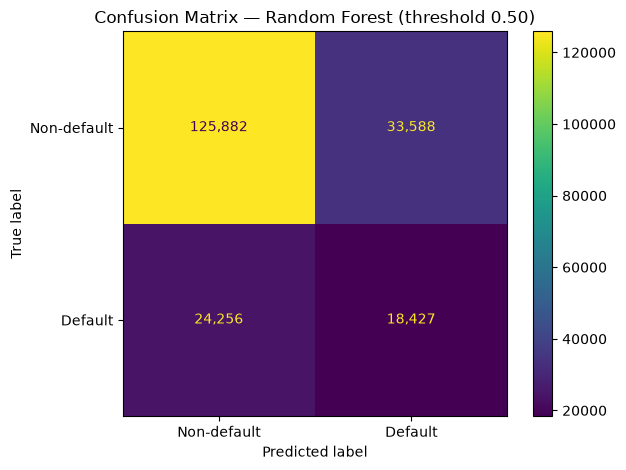

Confusion matrix [[TN, FP], [FN, TP]]:
[[125882  33588]
 [ 24256  18427]]


In [12]:
best_name = str(validation_results.iloc[0]["model"])
best_model = fitted_models[best_name]
test_X = X_test

test_result, test_probabilities, test_predictions = compute_metrics(best_model, test_X, y_test, best_name)
print("Selected model:", best_name)
print("Held-out test metrics:")
display(pd.DataFrame([test_result]).set_index("model").T.rename(columns={best_name: "Result"}).assign(
    Result=lambda x: x["Result"].map(lambda v: f"{v:.4f}" if isinstance(v, (int, float, np.number)) else v)
))

print(classification_report(
    y_test, test_predictions, labels=[0, 1],
    target_names=["Non-default", "Default"], digits=4, zero_division=0
))

cm = confusion_matrix(y_test, test_predictions, labels=[0, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Non-default", "Default"])
disp.plot(values_format=",")
plt.title(f"Confusion Matrix — {best_name} (threshold 0.50)")
plt.tight_layout()
plt.show()

print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(cm)


## 7. EDA findings and interpretation

Use the charts above to write dataset-specific findings for the final report. For this dataset, the target distribution previously observed was approximately **80.0% non-default and 20.0% default**, so accuracy alone can be misleading. The sample plots also showed substantial missingness in `desc`, variation in default rates across loan purposes, home-ownership groups, employment-length categories, states, and across origination months. These are descriptive associations; validate group sizes and feature availability before making claims.

## 8. Final results and conclusion

The final model is selected by **validation PR-AUC**, then reported on the separate held-out test set. Record the actual outputs from the run below rather than relying on previously observed results, because reruns or dataset changes can change metrics.

In [13]:
summary_metrics = pd.DataFrame([{
    "Chosen model": best_name,
    "Accuracy": test_result["accuracy"],
    "Precision": test_result["precision"],
    "Recall": test_result["recall"],
    "F1-score": test_result["f1"],
    "ROC-AUC": test_result["roc_auc"],
    "PR-AUC": test_result["pr_auc"],
}])
display(summary_metrics.style.format({
    "Accuracy": "{:.2%}", "Precision": "{:.2%}", "Recall": "{:.2%}",
    "F1-score": "{:.2%}", "ROC-AUC": "{:.4f}", "PR-AUC": "{:.4f}"
}))

print(
    f"Conclusion: {best_name} was selected because it had the highest validation PR-AUC. "
    f"On the held-out test set, accuracy was {test_result['accuracy']:.2%}, "
    f"precision {test_result['precision']:.2%}, recall {test_result['recall']:.2%}, "
    f"F1-score {test_result['f1']:.2%}, ROC-AUC {test_result['roc_auc']:.4f}, "
    f"and PR-AUC {test_result['pr_auc']:.4f}. Interpret these metrics with the "
    "confusion matrix and the project's false-positive/false-negative trade-off."
)


,Chosen model,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Random Forest,71.39%,35.43%,43.17%,38.92%,0.6806,0.3468


Conclusion: Random Forest was selected because it had the highest validation PR-AUC. On the held-out test set, accuracy was 71.39%, precision 35.43%, recall 43.17%, F1-score 38.92%, ROC-AUC 0.6806, and PR-AUC 0.3468. Interpret these metrics with the confusion matrix and the project's false-positive/false-negative trade-off.


## 9. Save model and reports

This cell saves the selected model and evaluation artifacts in `artifacts/`. The prediction script expects the saved model bundle at `artifacts/loan_default_model.joblib`.


In [14]:
ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(parents=True, exist_ok=True)

joblib.dump({
    "model": best_model,
    "model_name": best_name,
    "feature_columns": list(X_train.columns),
    "categorical_columns": [],
    "threshold": 0.5,
    "target": TARGET,
    "split_method": split_method,
}, ARTIFACTS / "loan_default_model.joblib")

validation_results.to_csv(ARTIFACTS / "validation_model_comparison.csv", index=False)
pd.DataFrame([test_result]).to_csv(ARTIFACTS / "test_metrics.csv", index=False)
pd.DataFrame({
    "actual_default": y_test.to_numpy(),
    "predicted_default": test_predictions,
    "default_probability": test_probabilities,
}).to_csv(ARTIFACTS / "test_predictions.csv", index=False)

metadata = {
    "rows": int(len(df)),
    "target": TARGET,
    "features": list(X_train.columns),
    "selected_model": best_name,
    "split_method": split_method,
    "test_metrics": {k: (float(v) if isinstance(v, (np.integer, np.floating)) else v) for k, v in test_result.items()},
    "threshold": 0.5,
    "note": "Review feature definitions to ensure all predictors are available at loan application time."
}
with open(ARTIFACTS / "run_metadata.json", "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=2, allow_nan=True)

print(f"Saved model and reports to: {ARTIFACTS.resolve()}")


Saved model and reports to: C:\Users\abhis\Downloads\loan_default_prediction_project\loan_default_prediction_project\artifacts


## Submission checklist

- [ ] Run all notebook cells from top to bottom in the project virtual environment.
- [ ] Confirm the dataset path and target encoding.
- [ ] Inspect EDA charts and write concise, data-supported observations.
- [ ] Review feature definitions for target leakage and application-time availability.
- [ ] Include the actual test metrics table in the one-page summary.
- [ ] Submit this `.ipynb` notebook and, if required, export it to HTML/PDF.

**Limitations:** The test precision in the previous run was about 32.6% and recall about 60.0% at threshold 0.50. This means many predicted defaults were false positives, while some actual defaults were missed. A threshold tuned on validation data may change that trade-off. Do not treat this educational model as a real-world lending decision system without further validation, fairness checks, calibration, compliance review, and monitoring.
